# Linear Regression
---

*Part of my ML learning adventure - `Notebook 02` of the Google ML Crash Course*

> **Source:** [Google Machine Learning Crash Course](https://developers.google.com/machine-learning/crashcourse) - *Linear Regression*
> **Status:** ✅ Complete
> **Date:** October 2026

**Learning Objectives**:

* Explain a loss function and how it works
* Define and describe how gradient descent finds the optimal model parameters
* Describe how to tune hyperparameters to efficiently train a linear model


## Introduction

**Linear regression** is a statistical technique used to find the relationship between variables. In an ML context, linear regression finds the relationship between `features` and a `label`.

**For example**, suppose we want to predict a car's fuel efficiency in miles per gallon based on how heavy the car is, and we have the following dataset:

In [8]:
import pandas as pd 
import matplotlib.pyplot as plt

df = pd.DataFrame({'Pounds in 1000s': [3.5, 3.69, 3.44, 3.43, 4.34, 4.42, 2.37],
                   'Miles per gallon': [18, 15, 18, 16, 15, 14, 24]})

In [10]:
display(df)

,Pounds in 1000s,Miles per gallon
0,3.50,18
1,3.69,15
2,3.44,18
3,3.43,16
4,4.34,15
5,4.42,14
6,2.37,24


If these points are plotted, we can get the following graph:

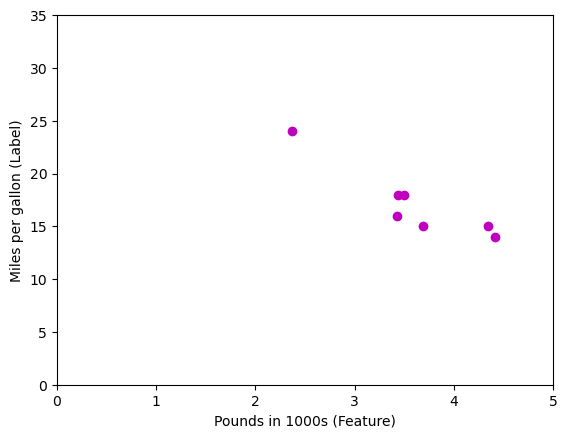

In [19]:
plt.plot(df['Pounds in 1000s'], df['Miles per gallon'], "mo")
plt.xlabel("Pounds in 1000s (Feature)")
plt.ylabel("Miles per gallon (Label)")
plt.xlim(0, 5)
plt.ylim(0, 35);

A model can be created by drawing a best fit line through the points:

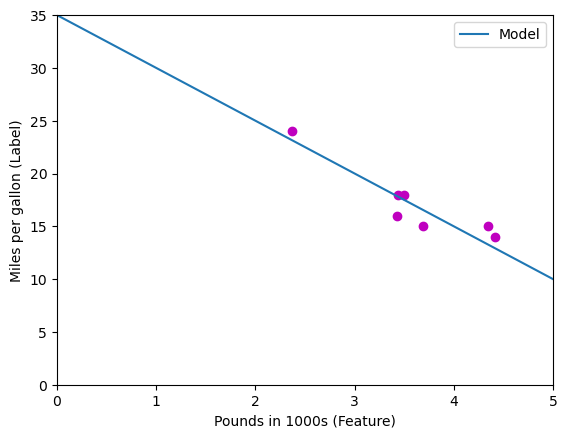

In [28]:
# plotting the datapoints
plt.plot(df['Pounds in 1000s'], df['Miles per gallon'], "mo")
# plotting the model line
plt.plot([0, 5], [35, 10], label = "Model")

plt.legend()
plt.xlabel("Pounds in 1000s (Feature)")
plt.ylabel("Miles per gallon (Label)")
plt.xlim(0, 5)
plt.ylim(0, 35);

## Equation

In algebraic terms, the model would be defined as $$y = mx + b$$ where, according to our dataset:

* `y` is miles per gallon - the value we want to predict
* `m` is the slope of the line
* `x` is weight in pounds - our input value
* `b` is the y-intercept

In Machine Learning, the equation for a linear regression model is written as follows:

$$y' = b + w_{1}x_{1}$$

* $y'$ is the predicted label - the output
* $b$ is the **bias** of the model. Bias is the same concept as the y-intercept in the algebraic equation for a line. In ML, bias is sometimes referred to as $w_{0}$. It's a parameter of the model that's calculated during training.
* $w_{1}$ is the weight of the feature. Weight is the same concept as the slope $m$ in the algebraic equation for a line. Weight is a **parameter** of the model and is calculated during training.
* $x_{1}$ is a **feature** - the input.

During training, the model calculates the weight and bias that produce the best model.

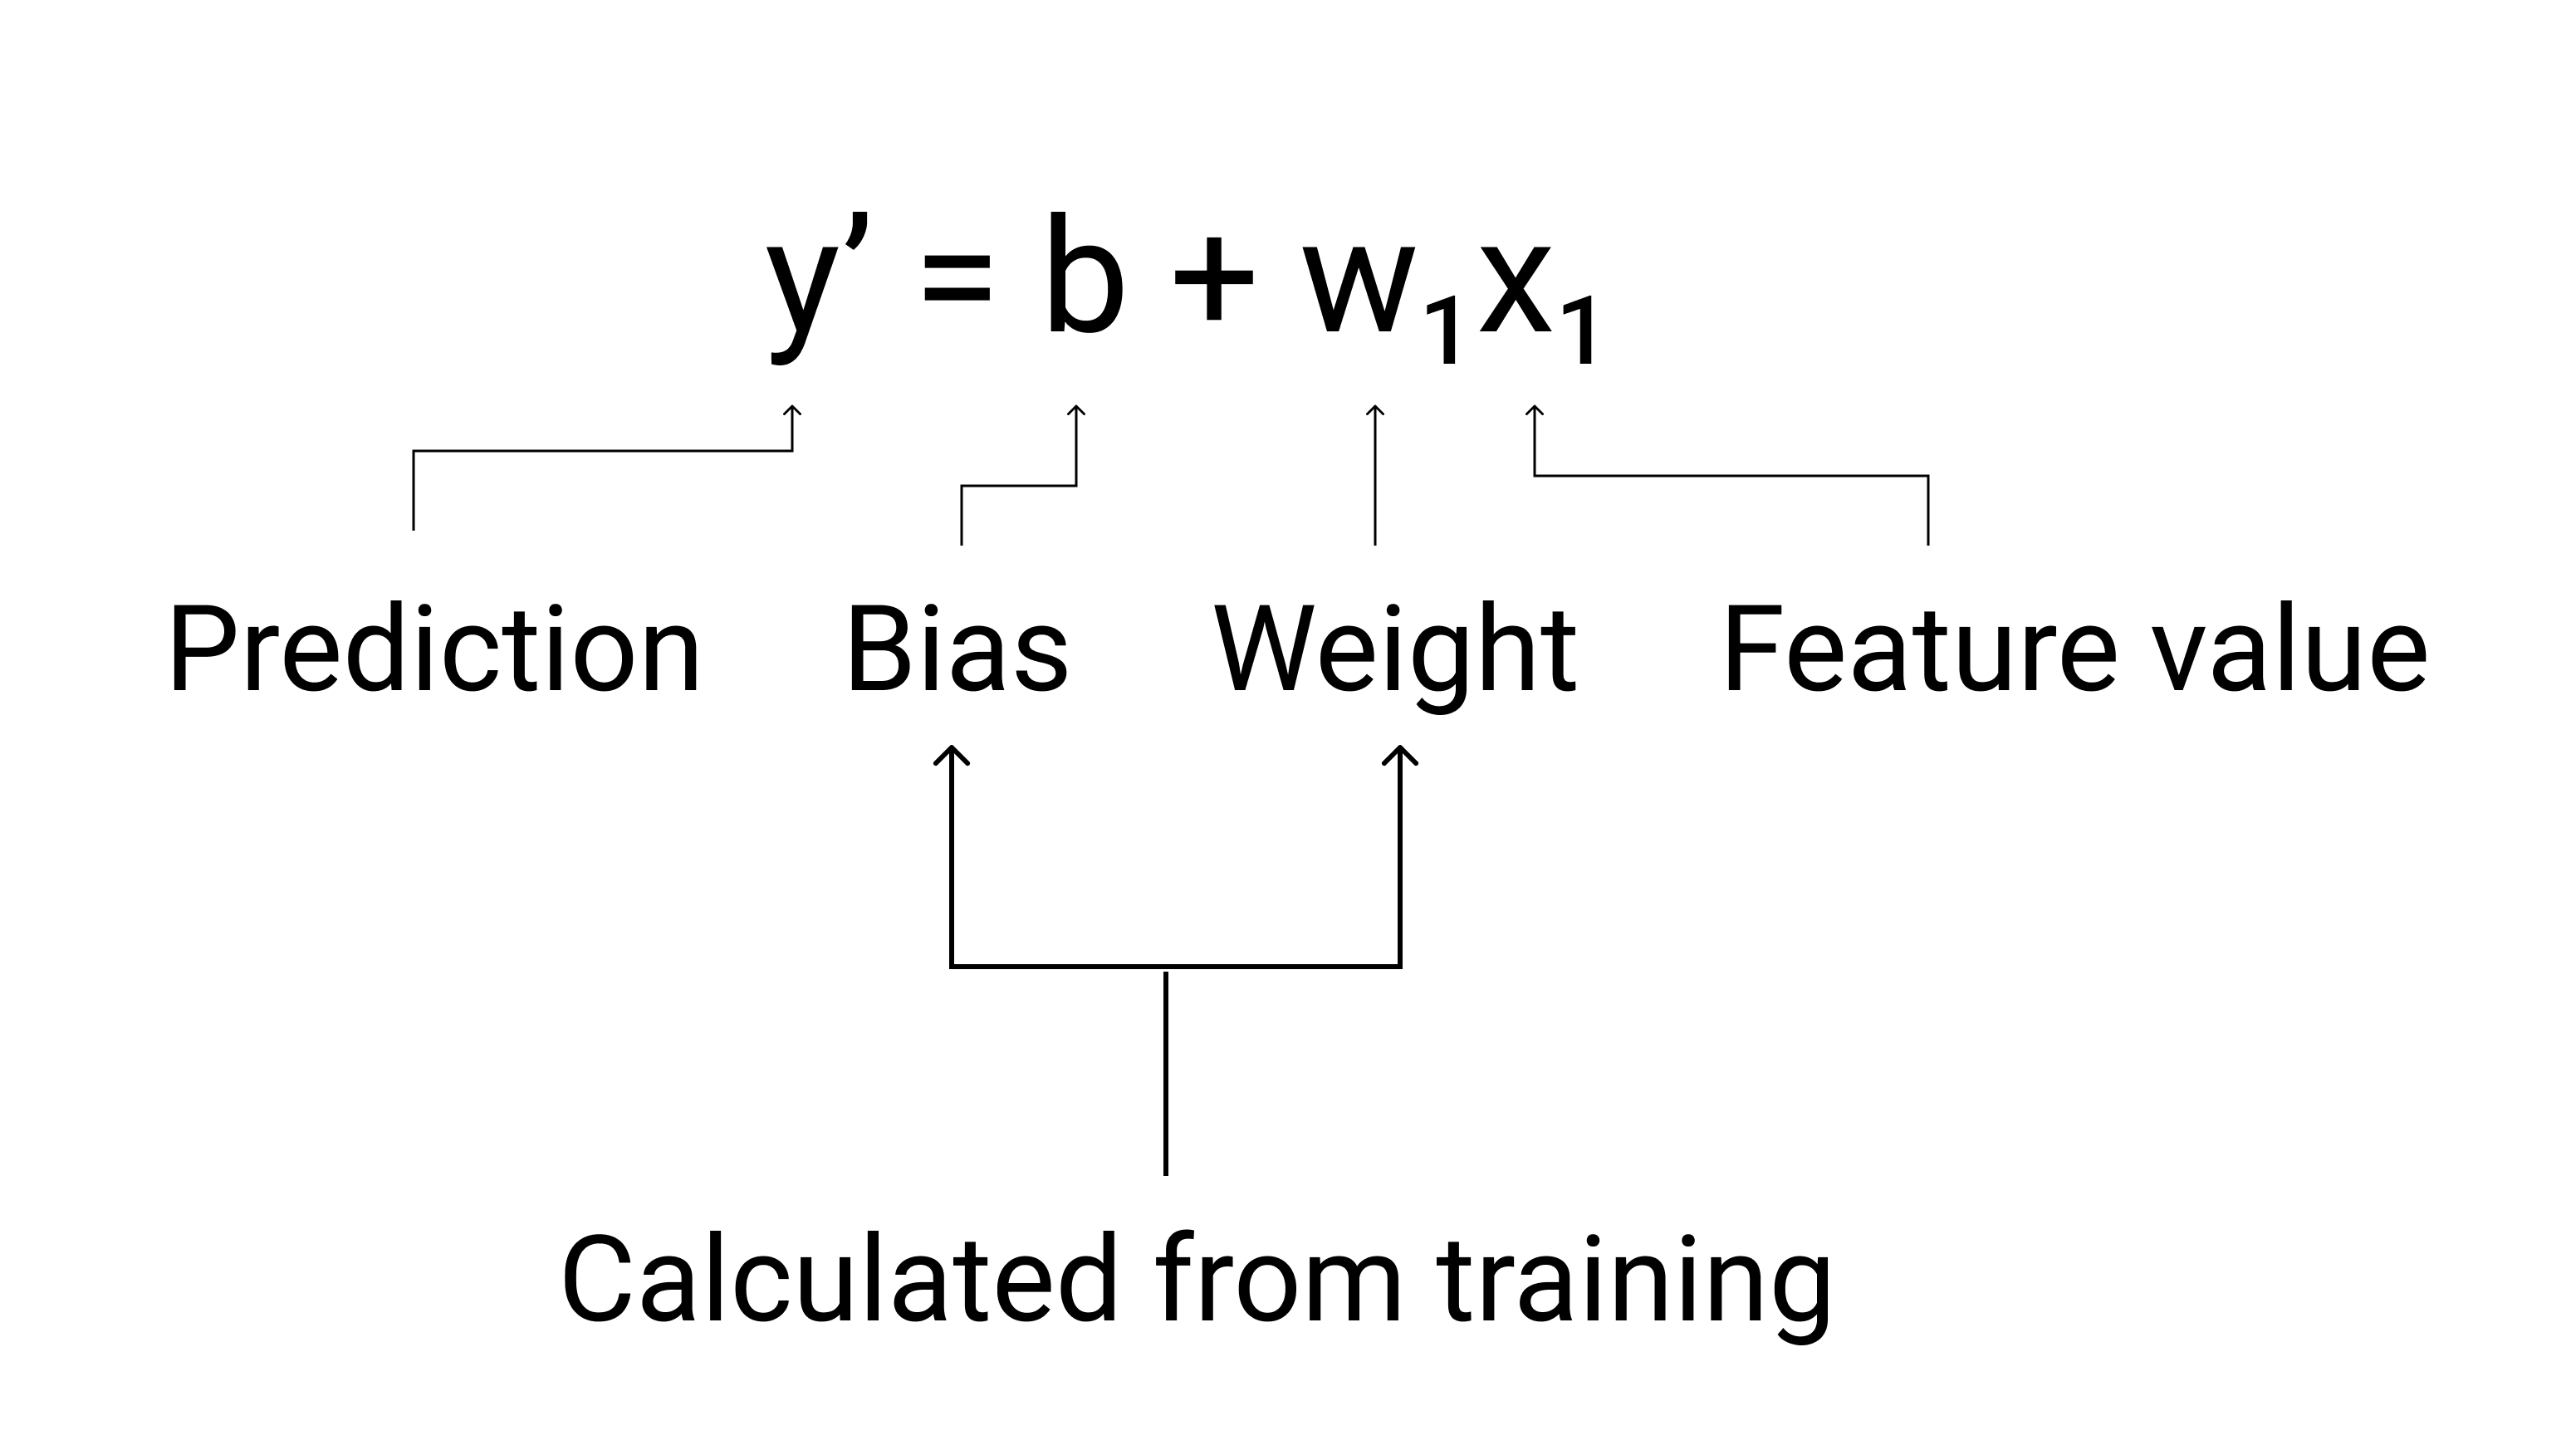

In the example, the bias and weight can be calculated from the line drawn. The bias is 34 (where the line intersects the y-axis), and the weight is -4.6 (the slope of the line). 

The model would be defined as $y' = 34 + (-4.6)(x_{1})$ and it can be used to make predictions.

For instance, using this model, a 4000-pound car would have a predicted fuel efficiency of 15.6 miles per gallon.

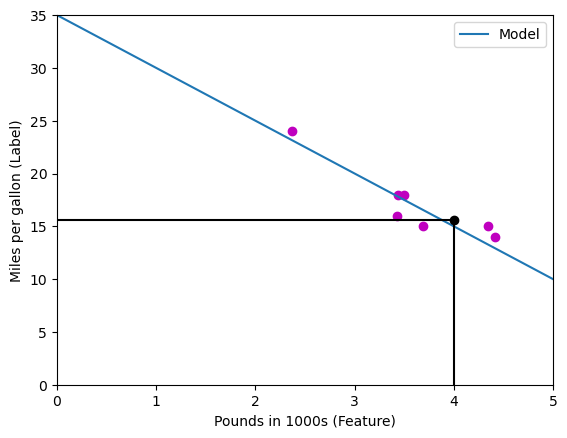

In [56]:
# plotting the datapoints
plt.plot(df['Pounds in 1000s'], df['Miles per gallon'], "mo")
# plotting the model line
plt.plot([0, 5], [35, 10], label = "Model")
# plotting the unseen datapoint
plt.plot(4, 15.6, "ko")
plt.plot([4, 4], [0, 15.6], "k")
plt.plot([0, 4], [15.6, 15.6], "k")

plt.legend()
plt.xlabel("Pounds in 1000s (Feature)")
plt.ylabel("Miles per gallon (Label)")
plt.xlim(0, 5)
plt.ylim(0, 35);

## Models with Multiple Features

Although the example in this section uses only one feature - the weight of the car - a more sophisticated model might rely on multiple features, each having a separate weight ($w_{1}$, $w_{2}$ etc).

**For example**, a model that relies on five features would be written as:

$$y' = b + w_{1}x_{1} + w_{2}x_{2} + w_{3}x_{3} + w_{4}x_{4} + w_{5}x_{5}$$

A model predicting gas mileage could additionally use features such as the following:

* engine displacement
* acceleration
* number of cylinders
* horsepower

In that case, the model would be written as:

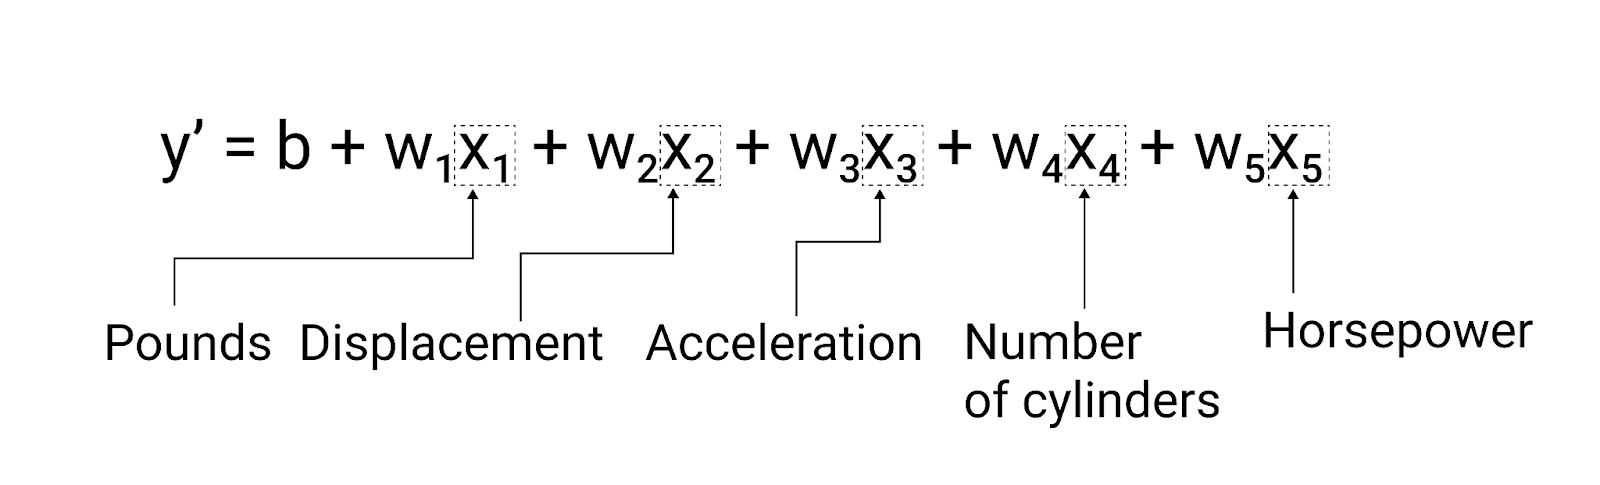

By graphing a couple of these features, it can be seen that they also have a linear relationship to the label, miles per gallon:

In [67]:
df['Horsepower'] = [240, 300, 275, 310, 325, 375, 220]
df['Acceleration'] = [18, 12, 15, 10, 10, 8, 20]

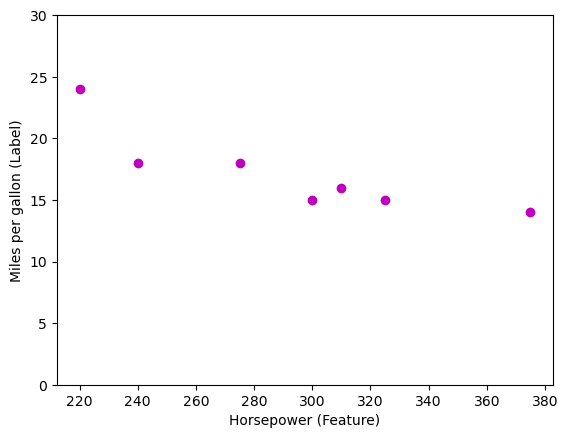

In [73]:
# plotting the datapoints
plt.plot(df['Horsepower'], df['Miles per gallon'], "mo")

plt.xlabel("Horsepower (Feature)")
plt.ylabel("Miles per gallon (Label)")
#plt.xlim(0, 5)
plt.ylim(0, 30);

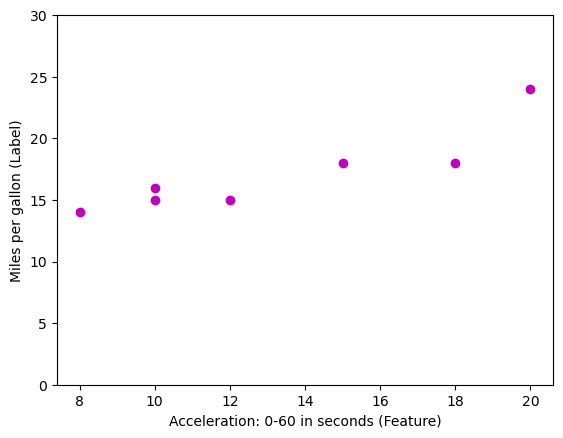

In [75]:
# plotting the datapoints
plt.plot(df['Acceleration'], df['Miles per gallon'], "mo")

plt.xlabel("Acceleration: 0-60 in seconds (Feature)")
plt.ylabel("Miles per gallon (Label)")
#plt.xlim(0, 5)
plt.ylim(0, 30);